# Advanced Algorithms: Advanced Data Structures

> **Prerequisite:** [`dsa/06` Trees, BSTs and heaps](../dsa/06_trees_bst_and_heaps.ipynb) (binary search trees, rotations, heaps) and [`dsa/11` Tries, strings and range queries](../dsa/11_advanced_tries_strings_and_range_queries.ipynb) (segment tree, Fenwick tree, sparse table).
>
> **Who is this for:** you know the classic structures (arrays, hash maps, BSTs, heaps) and want the specialised ones that sit inside search engines, genome tools, databases, vector indexes and text editors. It is also for students taking a second data-structures course and for senior-level interviews ("design a calendar that detects conflicts", "find the nearest restaurant").
>
> **What you will learn:**
> - **Range queries without updates and with updates**: the sparse table (O(1) RMQ) and **sqrt decomposition**, compared with the segment tree
> - **Suffix arrays** (prefix doubling, $O(n \log^2 n)$) and the **LCP array** (Kasai, $O(n)$): substring search, longest repeated substring, counting distinct substrings
> - **Interval trees** (an augmented BST) for overlap queries: calendars and genomic regions
> - **KD-trees** from scratch: build, nearest-neighbour search with pruning, and the **curse of dimensionality**
> - **Red-black trees** explained through **2-3-4 trees**, and a **left-leaning red-black (LLRB)** insert implementation with invariant checks
> - **Persistent data structures** by path copying: every old version stays available
> - An **LSM tree** in miniature (memtable, SSTables, Bloom filters, compaction) and how it differs from a B+ tree
> - **Gap buffers and ropes** for text editing
>
> **Prerequisites:** [Python basics](../../01_Python/01_basic.ipynb) (classes, recursion); [`dsa/06`](../dsa/06_trees_bst_and_heaps.ipynb); Big-O from [`dsa/01`](../dsa/01_complexity_analysis_and_recursion.ipynb).
>
> **Time needed:** about 3–4 hours.
>
> **Runs on:** CPU, no API key, no internet. The whole notebook runs in about one to two minutes.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep. It follows CLRS (4th ed.) ch. 13 (red-black trees) and §17.3 (interval trees), Sedgewick & Wayne, *Algorithms* (4th ed.) §3.3 (balanced search trees), Gusfield, *Algorithms on Strings, Trees and Sequences* (suffix arrays), and O'Neil et al. (1996) for LSM trees.

## Explained simply

A **data structure** is a way of arranging information so that the questions you care about are quick to answer. A phone book sorted by name makes "what is Ali's number?" fast, but "who lives on Park Road?" slow; a different arrangement would make the second question fast instead. This notebook collects clever arrangements for special questions: "which meetings clash with this one?", "where does this word appear in a huge text?", "which shop is nearest to me?", "what did this document look like ten edits ago?". A library that keeps books on shelves by topic, and a supermarket that groups products by aisle, are everyday versions of the same idea: a bit of organising up front saves a lot of searching later.

**Tiny example.** You have 5 meetings: 9–10, 10:30–12, 13–14, 14:30–16 and 15–15:30. A new meeting is proposed for 14:00–15:30. Two time ranges clash when each starts before the other ends. Checking: 14:30–16 starts at 14:30 (before 15:30) and ends at 16 (after 14:00), so it clashes; so does 15–15:30. The 13–14 meeting ends exactly at 14:00, so it does not. An **interval tree** finds these two clashes without looking at every meeting, which matters when there are millions of them.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Suffix array | all endings of a text, sorted like a dictionary, so any word can be found by binary search | search engines, DNA analysis, removing repeated text from LLM training data |
| KD-tree | splits space into boxes so "nearest point" searches can skip far-away boxes | "restaurants near me", k-nearest-neighbour models |
| LSM tree | writes new data quickly in batches and tidies it up later | databases behind feature stores, logs and chat apps |

### How this notebook is different from `dsa/06` and `dsa/11`
[`dsa/06`](../dsa/06_trees_bst_and_heaps.ipynb) builds plain BSTs and AVL-style rotations; [`dsa/11`](../dsa/11_advanced_tries_strings_and_range_queries.ipynb) builds tries, the segment tree, the Fenwick tree and the sparse table. Here we only *recap* the sparse table (in one cell) and spend our time on structures those notebooks do not cover. The **B+ tree** is covered in [DBMS 07](../../13_Databases/00_dbms_fundamentals/07_indexing_b_trees_and_hashing.ipynb); we compare the LSM tree against it.

## Table of contents
0. Setup
1. Range queries: sparse table and sqrt decomposition
2. Suffix arrays and the LCP array
3. Interval trees
4. KD-trees and the curse of dimensionality
5. Red-black trees via 2-3-4 trees (LLRB)
6. Persistent data structures
7. An LSM tree in miniature
8. Gap buffers and ropes
9. Comparison table and how this connects to modern AI
10. Recap, practice problems, further reading

---
## 0. Setup

> 💬 **In plain English:** we load the tools and a timing helper.

In [1]:
import math, random, sys, time, bisect, heapq, itertools, json, os, tempfile, shutil, hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

random.seed(42)
np.random.seed(42)
sys.setrecursionlimit(10_000)
pd.set_option("display.width", 140)
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=PALETTE), "lines.linewidth": 2,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold", "figure.dpi": 100})


def best_time(fn, *args, repeat=3):
    best = float("inf")
    for _ in range(repeat):
        t0 = time.perf_counter(); fn(*args); best = min(best, time.perf_counter() - t0)
    return best


CHECKS = Counter()
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| networkx", nx.__version__)

Python 3.12.3 | numpy 2.4.6 | networkx 3.7


---
## 1. Range queries: sparse table and sqrt decomposition

> 💬 **In plain English:** pre-compute a little so that "what is the smallest or total value between positions l and r?" is quick.

**Intuition.** You have daily temperatures for 10 years and will be asked thousands of questions like "coldest day between day 1,200 and day 3,400?" or "total rainfall in that period?". Scanning the range each time is $O(n)$ per question. Pre-computing helps.

**Sparse table (recap from `dsa/11`).** Store the minimum of every block whose length is a power of two: $\text{st}[j][i] = \min(a[i..i+2^j-1])$. Any range $[l, r]$ is covered by **two overlapping** power-of-two blocks, and overlap does not matter for `min` (it is **idempotent**: $\min(x, x) = x$). Build $O(n \log n)$, query $O(1)$, but **no updates**, and it does not work for sums (overlap would double-count).

**Sqrt decomposition.** Cut the array into about $\sqrt n$ blocks of size $b \approx \sqrt n$ and store each block's sum. A query adds whole blocks in the middle plus at most $2b$ single elements at the ends: $O(\sqrt n)$. A point update changes one element and one block sum: $O(1)$. Simple, flexible (works for many operations, and is the basis of **Mo's algorithm** for offline queries), but slower than a segment tree's $O(\log n)$.

```
array : [5 2 7 | 1 9 3 | 8 6 4 | 2 7 1]      block size b = 3
blocks:  14      13      18      10
sum(1..8) = (2 + 7) + 13 + (8 + 6 + 4) = 40   -> 2 partial pieces + 1 whole block
```

In [2]:
class SparseTableMin:
    def __init__(self, a):
        n = len(a)
        self.log = [0] * (n + 1)
        for i in range(2, n + 1):
            self.log[i] = self.log[i // 2] + 1          # floor(log2(i))
        self.st = [list(a)]
        j = 1
        while (1 << j) <= n:
            prev, half = self.st[-1], 1 << (j - 1)
            self.st.append([min(prev[i], prev[i + half]) for i in range(n - (1 << j) + 1)])
            j += 1

    def query(self, l, r):                              # inclusive range
        j = self.log[r - l + 1]
        return min(self.st[j][l], self.st[j][r - (1 << j) + 1])   # two overlapping blocks


class SqrtSum:
    def __init__(self, a):
        self.a = list(a)
        self.b = max(1, int(math.sqrt(len(a))))
        self.blocks = [sum(self.a[i:i + self.b]) for i in range(0, len(a), self.b)]

    def update(self, i, v):                             # O(1)
        self.blocks[i // self.b] += v - self.a[i]
        self.a[i] = v

    def query(self, l, r):                              # O(sqrt n)
        s, i = 0, l
        while i <= r and i % self.b:                    # left partial block
            s += self.a[i]; i += 1
        while i + self.b - 1 <= r:                      # whole blocks
            s += self.blocks[i // self.b]; i += self.b
        while i <= r:                                   # right partial block
            s += self.a[i]; i += 1
        return s


class SegTreeSum:
    """Iterative (bottom-up) segment tree, for comparison."""
    def __init__(self, a):
        self.n = len(a)
        self.t = [0] * self.n + list(a)
        for i in range(self.n - 1, 0, -1):
            self.t[i] = self.t[2 * i] + self.t[2 * i + 1]

    def update(self, i, v):
        i += self.n; self.t[i] = v
        while i > 1:
            i //= 2; self.t[i] = self.t[2 * i] + self.t[2 * i + 1]

    def query(self, l, r):
        s, l, r = 0, l + self.n, r + self.n + 1
        while l < r:
            if l & 1: s += self.t[l]; l += 1
            if r & 1: r -= 1; s += self.t[r]
            l //= 2; r //= 2
        return s


demo = [5, 2, 7, 1, 9, 3, 8, 6, 4, 2, 7, 1]
print("sqrt decomposition sum(1..8) =", SqrtSum(demo).query(1, 8), "| sparse-table min(1..8) =", SparseTableMin(demo).query(1, 8))
rr = random.Random(1)
for _ in range(300):                                    # random tests against plain Python
    a = [rr.randint(-50, 50) for _ in range(rr.randint(1, 80))]
    sp, sq, sg = SparseTableMin(a), SqrtSum(a), SegTreeSum(a)
    for _ in range(30):
        if rr.random() < 0.3:
            i, v = rr.randrange(len(a)), rr.randint(-50, 50)
            a[i] = v; sq.update(i, v); sg.update(i, v); sp = SparseTableMin(a)   # sparse table: rebuild
        l = rr.randrange(len(a)); r = rr.randrange(l, len(a))
        assert sp.query(l, r) == min(a[l:r + 1]) and sq.query(l, r) == sg.query(l, r) == sum(a[l:r + 1])
        CHECKS["range queries"] += 1

n = 100_000
a = [rr.randint(0, 1000) for _ in range(n)]
queries = [(l, rr.randrange(l, n)) for l in (rr.randrange(n) for _ in range(5_000))]
sp, sq, sg = SparseTableMin(a), SqrtSum(a), SegTreeSum(a)
rows = [{"structure": "sparse table (min)", "build (s)": best_time(SparseTableMin, a, repeat=1), "5k queries (s)": best_time(lambda: [sp.query(l, r) for l, r in queries], repeat=1), "update": "rebuild O(n log n)"},
        {"structure": "sqrt decomposition (sum)", "build (s)": best_time(SqrtSum, a, repeat=1), "5k queries (s)": best_time(lambda: [sq.query(l, r) for l, r in queries], repeat=1), "update": "O(1)"},
        {"structure": "segment tree (sum)", "build (s)": best_time(SegTreeSum, a, repeat=1), "5k queries (s)": best_time(lambda: [sg.query(l, r) for l, r in queries], repeat=1), "update": "O(log n)"},
        {"structure": "plain slicing (sum)", "build (s)": 0.0, "5k queries (s)": best_time(lambda: [sum(a[l:r + 1]) for l, r in queries], repeat=1), "update": "O(1)"}]
print(pd.DataFrame(rows).round(4).to_string(index=False))

sqrt decomposition sum(1..8) = 40 | sparse-table min(1..8) = 1


               structure  build (s)  5k queries (s)             update
      sparse table (min)     2.1040          0.0166 rebuild O(n log n)
sqrt decomposition (sum)     0.0133          2.2480               O(1)
      segment tree (sum)     0.1765          0.1454           O(log n)
     plain slicing (sum)     0.0000         12.4887               O(1)


**What just happened?** The worked example gives $40$, and all three structures agreed with plain Python on 9,000 random queries mixed with updates. On $n = 100{,}000$ the sparse table answers 5,000 minimum queries fastest (two lookups each) but must be rebuilt after any change; the segment tree is fastest for sums with updates; sqrt decomposition sits in between ($\sqrt{n} \approx 316$ blocks) and is the easiest to write correctly in an exam.

| structure | build | query | point update | operations |
|---|---|---|---|---|
| prefix sums | $O(n)$ | $O(1)$ | $O(n)$ | invertible (sum, xor) |
| sparse table | $O(n \log n)$ | $O(1)$ | rebuild | idempotent (min, max, gcd) |
| sqrt decomposition | $O(n)$ | $O(\sqrt n)$ | $O(1)$ | almost anything |
| segment tree | $O(n)$ | $O(\log n)$ | $O(\log n)$ | any associative op; range updates with lazy propagation |
| Fenwick tree | $O(n)$ | $O(\log n)$ | $O(\log n)$ | invertible (sum) |

---
## 2. Suffix arrays and the LCP array

> 💬 **In plain English:** sort all endings of a text once, then any search in the text becomes a quick dictionary lookup.

**Intuition.** Write down every **suffix** of a text (the text starting at position 0, at position 1, ...) and sort them alphabetically, like words in a dictionary. Every substring of the text is the beginning of some suffix, and in sorted order all suffixes that start with the same pattern sit **next to each other**. So substring search becomes binary search.

**Definition.** The **suffix array** SA of a string $s$ of length $n$ is the permutation of $0..n-1$ that lists the starting positions of the suffixes in lexicographic order. The **LCP array** stores $\text{LCP}[i]$ = length of the longest common prefix of the suffixes at SA$[i-1]$ and SA$[i]$.

Worked example, $s$ = `banana`:

| rank $i$ | SA[i] | suffix | LCP[i] (with previous) |
|---|---|---|---|
| 0 | 5 | a | – |
| 1 | 3 | ana | 1 |
| 2 | 1 | anana | 3 |
| 3 | 0 | banana | 0 |
| 4 | 4 | na | 0 |
| 5 | 2 | nana | 2 |

**Prefix doubling (Manber & Myers, 1990).** Give each suffix a rank by its first character. Then repeatedly sort suffixes by the **pair** (rank of first $k$ characters, rank of the next $k$ characters): that sorts by the first $2k$ characters. After $\lceil\log_2 n\rceil$ rounds all ranks are distinct. With a comparison sort each round costs $O(n \log n)$: total $O(n \log^2 n)$ (radix sort gives $O(n \log n)$; SA-IS gives $O(n)$).

**Kasai's algorithm (2001)** computes LCP in $O(n)$ using one fact: if the suffix at $i$ shares $h$ characters with its predecessor in SA, the suffix at $i + 1$ shares at least $h - 1$ with its own predecessor. So $h$ never drops by more than 1 per step.

In [3]:
def suffix_array_naive(s):
    return sorted(range(len(s)), key=lambda i: s[i:])        # O(n^2 log n) worst case: each comparison can be O(n)


def suffix_array_doubling(s):
    n = len(s)
    if n == 0:
        return []
    rank = [ord(c) for c in s]
    sa = list(range(n))
    k = 1
    while True:
        key = lambda i: (rank[i], rank[i + k] if i + k < n else -1)   # (first k chars, next k chars)
        sa.sort(key=key)
        new_rank = [0] * n
        for j in range(1, n):
            new_rank[sa[j]] = new_rank[sa[j - 1]] + (key(sa[j]) != key(sa[j - 1]))
        rank = new_rank
        if rank[sa[-1]] == n - 1:                               # all ranks distinct -> fully sorted
            return sa
        k *= 2


def lcp_kasai(s, sa):
    n = len(s)
    rank = [0] * n
    for i, p in enumerate(sa):
        rank[p] = i
    lcp, h = [0] * n, 0
    for i in range(n):                                          # suffixes in TEXT order
        if rank[i] > 0:
            j = sa[rank[i] - 1]                                 # predecessor in sorted order
            while i + h < n and j + h < n and s[i + h] == s[j + h]:
                h += 1
            lcp[rank[i]] = h
            if h > 0:
                h -= 1                                          # the key fact: drop by at most 1
        else:
            h = 0
    return lcp


s = "banana"
sa = suffix_array_doubling(s)
lcp = lcp_kasai(s, sa)
print(pd.DataFrame({"SA": sa, "suffix": [s[i:] for i in sa], "LCP": lcp}).to_string())

rr = random.Random(2)
for _ in range(500):
    t = "".join(rr.choice("ab" if rr.random() < 0.5 else "acgt") for _ in range(rr.randint(1, 60)))
    sa_t = suffix_array_doubling(t)
    assert sa_t == suffix_array_naive(t)
    lc = lcp_kasai(t, sa_t)
    assert all(lc[i] == len(os.path.commonprefix([t[sa_t[i - 1]:], t[sa_t[i]:]])) for i in range(1, len(t)))
    CHECKS["suffix array + LCP"] += 1
print("prefix doubling == naive sort, Kasai LCP == direct comparison, on 500 random strings")

   SA  suffix  LCP
0   5       a    0
1   3     ana    1
2   1   anana    3
3   0  banana    0
4   4      na    0
5   2    nana    2


prefix doubling == naive sort, Kasai LCP == direct comparison, on 500 random strings


### Applications
With SA and LCP many string questions become one-liners:

| question | how | time |
|---|---|---|
| does pattern $p$ occur? where? | binary search for the block of suffixes starting with $p$ | $O(m \log n)$ |
| longest repeated substring | the maximum LCP value | $O(n)$ |
| number of distinct substrings | $\frac{n(n+1)}{2} - \sum \text{LCP}$ (each suffix adds its new prefixes) | $O(n)$ |
| longest common substring of $s$ and $t$ | SA of `s#t`, max LCP between neighbours from different strings | $O(n)$ after SA |

In [4]:
def find_all(s, sa, p):
    """All start positions of pattern p, by binary search on the suffix array."""
    lo = bisect.bisect_left(sa, p, key=lambda i: s[i:i + len(p)])
    hi = bisect.bisect_right(sa, p, key=lambda i: s[i:i + len(p)])
    return sorted(sa[lo:hi])


def longest_repeated_substring(s, sa, lcp):
    i = max(range(len(lcp)), key=lambda k: lcp[k], default=0)
    return s[sa[i]:sa[i] + lcp[i]] if lcp and lcp[i] > 0 else ""


def distinct_substrings(s, lcp):
    n = len(s)
    return n * (n + 1) // 2 - sum(lcp)


text = "to be or not to be that is the question to be"
sa_t, lcp_t = suffix_array_doubling(text), None
lcp_t = lcp_kasai(text, sa_t)
print("occurrences of 'to be':", find_all(text, sa_t, "to be"), "| str.find check:", [i for i in range(len(text)) if text.startswith("to be", i)])
print("longest repeated substring:", repr(longest_repeated_substring(text, sa_t, lcp_t)))
print("distinct substrings of 'banana':", distinct_substrings("banana", lcp_kasai("banana", suffix_array_doubling("banana"))),
      "| brute force:", len({"banana"[i:j] for i in range(6) for j in range(i + 1, 7)}))

for _ in range(300):
    t = "".join(rr.choice("abc") for _ in range(rr.randint(1, 40)))
    sa_r = suffix_array_doubling(t); lc = lcp_kasai(t, sa_r)
    assert distinct_substrings(t, lc) == len({t[i:j] for i in range(len(t)) for j in range(i + 1, len(t) + 1)})
    p = "".join(rr.choice("abc") for _ in range(rr.randint(1, 3)))
    assert find_all(t, sa_r, p) == [i for i in range(len(t)) if t.startswith(p, i)]
    lrs = longest_repeated_substring(t, sa_r, lc)
    best = max((len(t[i:j]) for i in range(len(t)) for j in range(i + 1, len(t) + 1) if t.count(t[i:j]) >= 2 or t.find(t[i:j], i + 1) != -1), default=0)
    assert len(lrs) == best
    CHECKS["suffix-array applications"] += 1

rows = []
for n in [500, 1000, 2000, 4000]:
    rand_s = "".join(rr.choice("acgt") for _ in range(n))
    rep_s = "ab" * (n // 2)                                    # highly repetitive: long common prefixes
    rows.append({"n": n, "naive random (s)": best_time(suffix_array_naive, rand_s, repeat=1), "doubling random (s)": best_time(suffix_array_doubling, rand_s, repeat=1),
                 "naive 'abab..' (s)": best_time(suffix_array_naive, rep_s, repeat=1), "doubling 'abab..' (s)": best_time(suffix_array_doubling, rep_s, repeat=1),
                 "naive: slice memory (MB)": n * (n + 1) / 2 / 1e6})
print(pd.DataFrame(rows).round(4).to_string(index=False))
for n in [10**5, 10**6]:
    print(f"n = {n:,}: the naive key function would materialise {n * (n + 1) / 2 / 1e9:,.0f} GB of suffix slices; prefix doubling needs O(n) memory")

occurrences of 'to be': [0, 13, 40] | str.find check: [0, 13, 40]
longest repeated substring: ' to be'
distinct substrings of 'banana': 15 | brute force: 15


   n  naive random (s)  doubling random (s)  naive 'abab..' (s)  doubling 'abab..' (s)  naive: slice memory (MB)
 500            0.0004               0.0088              0.0004                 0.0207                    0.1252
1000            0.0010               0.0336              0.0007                 0.0488                    0.5005
2000            0.0084               0.0493              0.0120                 0.1241                    2.0010
4000            0.0495               0.4705              0.0247                 0.2736                    8.0020
n = 100,000: the naive key function would materialise 5 GB of suffix slices; prefix doubling needs O(n) memory
n = 1,000,000: the naive key function would materialise 500 GB of suffix slices; prefix doubling needs O(n) memory


**What just happened?** Binary search on the suffix array found the three occurrences of "to be" (the same positions as a direct scan). The longest repeated substring is the suffix pair with the largest LCP, and `banana` has 15 distinct substrings both by formula and by brute force. All three applications passed 300 random tests.

The timing table holds a lesson about **constants vs asymptotics**. At these sizes the naive "sort the slices" method is *faster* in Python, even on the repetitive string `abab...` where every comparison is long, because slicing and string comparison run in optimised C while our prefix doubling runs Python code in every round. But look at the memory column: the naive key function creates all $n(n+1)/2$ characters of suffixes at once. That is 8 MB at $n = 4{,}000$, about 5 GB at $n = 10^5$ and 500 GB at $n = 10^6$, while prefix doubling uses $O(n)$ memory. For real inputs (a genome has $3 \times 10^9$ letters, a training corpus $10^{12}$ tokens) only the $O(n \log n)$ or $O(n)$ algorithms implemented in a compiled language (e.g. SA-IS, libdivsufsort) are usable.

> 🎓 **Exam / interview tip:** suffix array + LCP can replace a **suffix tree** for almost every application with about 4–5× less memory. Know the three classic uses: substring search, longest repeated substring, count of distinct substrings.

---
## 3. Interval trees

> 💬 **In plain English:** a search tree of time ranges that can skip whole groups which end too early.

**Intuition.** A calendar app must answer "does a new meeting from 14:00 to 15:30 clash with anything?" A genome browser must answer "which genes overlap the region 1,200,000–1,250,000?". Checking every stored interval is $O(n)$ per question.

**Definition (CLRS §17.3).** An **interval tree** is a BST of intervals keyed by their **start**, where every node is **augmented** with `max_end`, the largest end point in its subtree. We use **half-open** intervals $[a, b)$, which are natural for times (a meeting ending at 14:00 does not clash with one starting at 14:00): $[a, b)$ and $[c, d)$ overlap iff $a < d$ and $c < b$. (CLRS uses closed intervals; only the $<$ / $\le$ signs change.)

**Pruning rule for "find all intervals overlapping $[lo, hi]$":**
- if a subtree's `max_end` $\le lo$, nothing in it can overlap: skip it;
- if a node's start $\ge hi$, neither it nor its right subtree (larger starts) can overlap.

To keep the tree balanced whatever the insertion order we store the intervals in a **treap** (a BST whose nodes also carry random priorities and satisfy the heap property on them; see [notebook 01](01_amortized_and_randomized_algorithms.ipynb)). Rotations must recompute `max_end`, which is the general lesson of **augmenting** a data structure: the extra field must be maintainable during every structural change in $O(1)$.

In [5]:
class _INode:
    __slots__ = ("lo", "hi", "label", "prio", "max_end", "left", "right")
    def __init__(self, lo, hi, label, prio):
        self.lo, self.hi, self.label, self.prio = lo, hi, label, prio
        self.max_end, self.left, self.right = hi, None, None


def _fix(n):
    n.max_end = max(n.hi, n.left.max_end if n.left else -math.inf, n.right.max_end if n.right else -math.inf)


def _rot_right(n):
    l = n.left; n.left = l.right; l.right = n; _fix(n); _fix(l); return l


def _rot_left(n):
    r = n.right; n.right = r.left; r.left = n; _fix(n); _fix(r); return r


class IntervalTree:
    def __init__(self, seed=0):
        self.root, self.rng, self.size = None, random.Random(seed), 0

    def insert(self, lo, hi, label=None):
        def ins(n):
            if n is None:
                return _INode(lo, hi, label, self.rng.random())
            if (lo, hi) < (n.lo, n.hi):
                n.left = ins(n.left)
                if n.left.prio > n.prio: n = _rot_right(n)   # restore heap order on priorities
            else:
                n.right = ins(n.right)
                if n.right.prio > n.prio: n = _rot_left(n)
            _fix(n)
            return n
        self.root = ins(self.root); self.size += 1

    def overlapping(self, lo, hi):
        out, stack, visited = [], [self.root], 0
        while stack:
            n = stack.pop()
            if n is None or n.max_end <= lo:                 # whole subtree ends before the query starts
                continue
            visited += 1
            stack.append(n.left)
            if n.lo < hi:                                    # otherwise this node and its right subtree start too late
                if lo < n.hi:
                    out.append((n.lo, n.hi, n.label))
                stack.append(n.right)
        self.last_visited = visited
        return out

    def height(self):
        def h(n): return 0 if n is None else 1 + max(h(n.left), h(n.right))
        return h(self.root)


cal = IntervalTree()
for lo, hi, name in [(9, 10, "stand-up"), (10.5, 12, "design review"), (13, 14, "lunch talk"), (14.5, 16, "1:1"), (15, 15.5, "interview")]:
    cal.insert(lo, hi, name)
print("clashes with a new 14:00-15:30 meeting:", sorted(cal.overlapping(14, 15.5)))

rr = random.Random(3)
for _ in range(100):
    T, ivs = IntervalTree(seed=rr.randrange(10**6)), []
    for _ in range(rr.randint(0, 120)):
        lo = rr.randint(0, 500); hi = lo + rr.randint(0, 40)
        T.insert(lo, hi); ivs.append((lo, hi))
    for _ in range(30):
        qlo = rr.randint(0, 520); qhi = qlo + rr.randint(0, 50)
        assert sorted((a, b) for a, b, _ in T.overlapping(qlo, qhi)) == sorted((a, b) for a, b in ivs if a < qhi and qlo < b)
        CHECKS["interval tree"] += 1
print("interval tree == brute force on 3,000 random queries")

clashes with a new 14:00-15:30 meeting: [(14.5, 16, '1:1'), (15, 15.5, 'interview')]


interval tree == brute force on 3,000 random queries


In [6]:
# Genomics-style workload: 200k "genes" (short intervals on a 100M-base chromosome), sorted insertion order
rng = np.random.default_rng(4)
starts = np.sort(rng.integers(0, 100_000_000, 200_000))
lengths = rng.integers(1_000, 50_000, 200_000)
genes = IntervalTree(seed=1)
t0 = time.perf_counter()
for i, (s_, l_) in enumerate(zip(starts.tolist(), lengths.tolist())):
    genes.insert(s_, s_ + l_, f"gene{i}")
t_build = time.perf_counter() - t0
reads = [(int(x), int(x) + 150) for x in rng.integers(0, 100_000_000, 2_000)]   # sequencing reads of 150 bases
lo_arr, hi_arr = starts, starts + lengths
t_tree = best_time(lambda: [genes.overlapping(a, b) for a, b in reads], repeat=1)
visits = []
for a, b in reads[:200]:
    genes.overlapping(a, b); visits.append(genes.last_visited)
t_brute = best_time(lambda: [np.flatnonzero((lo_arr < b) & (a < hi_arr)) for a, b in reads], repeat=1)
hits = [len(genes.overlapping(a, b)) for a, b in reads]
print(f"tree height {genes.height()} for {genes.size:,} intervals inserted in sorted order (log2 n = {math.log2(genes.size):.1f}); build {t_build:.2f} s")
print(f"2,000 read queries: interval tree {t_tree:.3f} s (about {np.mean(visits):.0f} nodes visited per query) vs NumPy brute-force scan {t_brute:.3f} s")
print(f"average genes overlapping a read: {np.mean(hits):.2f}")

tree height 42 for 200,000 intervals inserted in sorted order (log2 n = 17.6); build 6.68 s
2,000 read queries: interval tree 0.154 s (about 92 nodes visited per query) vs NumPy brute-force scan 1.069 s
average genes overlapping a read: 51.37


**What just happened?** The calendar query returned the two clashing meetings (the 1:1 and the interview); the lunch talk ending exactly at 14:00 does not clash. On 3,000 random queries the tree matched brute force. With 200,000 genes inserted in **sorted** order (which would turn a plain BST into a linked list of height 200,000), the treap stayed shallow, about $2$–$3\times\log_2 n$, and each query visited only about 90 nodes out of 200,000 (about 51 of which were genuine overlaps that had to be reported anyway). That makes the pure-Python tree faster than a fully vectorised NumPy scan of all intervals (numbers printed above), and the gap widens as $n$ grows.

**Complexity:** insert $O(\log n)$ expected; reporting all $k$ overlaps costs $O(\min(n, (k+1)\log n))$ with our pruning (CLRS's "find one overlap" is $O(\log n)$). Space $O(n)$. Alternatives: a **centered interval tree** or a **segment tree over coordinates** (static data), and sorted-array **binning** schemes used by genomics tools.

---
## 4. KD-trees and the curse of dimensionality

> 💬 **In plain English:** split space into boxes to find the nearest point fast, and see why this stops working with many dimensions.

**Intuition.** To find the restaurant closest to you, you do not measure the distance to every restaurant in the country: you look in your neighbourhood first and ignore regions that are obviously too far. A **KD-tree** (Bentley, 1975) organises points so a computer can do the same.

**Definition.** A $k$-d tree recursively splits the points at the **median** along one coordinate, cycling through the axes ($x$, then $y$, then $x$, ...). Each node stores a point and its splitting axis; left subtree = smaller coordinate, right = larger. Build $O(n \log n)$, depth $O(\log n)$.

**Nearest-neighbour search with pruning:**
1. Descend to the side of each split containing the query (the "near" side) and remember the best distance $d^*$ found so far.
2. On the way back up, visit the **far** side only if the splitting plane is closer than $d^*$: $|q_{\text{axis}} - \text{split}| < d^*$. Otherwise the whole far subtree is pruned.

```
          (7,2) split x            query q = (9, 6)
         /          \              1. go right of x=7, then up of y=6 ...
     (5,4) y      (9,6) y          2. best so far = (9,6) at distance 0
     /    \        /               3. |9 - 7| = 2 > 0, so the left half is pruned
 (2,3)  (4,7)   (8,1)
```

In [7]:
class KDNode:
    __slots__ = ("idx", "axis", "left", "right")
    def __init__(self, idx, axis, left, right):
        self.idx, self.axis, self.left, self.right = idx, axis, left, right


class KDTree:
    def __init__(self, points):
        self.P = np.asarray(points, dtype=float)
        self.k = self.P.shape[1]
        self.root = self._build(list(range(len(self.P))), 0)

    def _build(self, idx, depth):
        if not idx:
            return None
        axis = depth % self.k
        idx.sort(key=lambda i: self.P[i, axis])          # median split (O(n log n) per level; O(n) with quickselect)
        m = len(idx) // 2
        return KDNode(idx[m], axis, self._build(idx[:m], depth + 1), self._build(idx[m + 1:], depth + 1))

    def nearest(self, q):
        q = np.asarray(q, dtype=float)
        best = [math.inf, -1]
        self.visited = 0
        def search(node):
            if node is None:
                return
            self.visited += 1
            p = self.P[node.idx]
            d = math.dist(p, q)
            if d < best[0]:
                best[0], best[1] = d, node.idx
            diff = q[node.axis] - p[node.axis]
            near, far = (node.left, node.right) if diff < 0 else (node.right, node.left)
            search(near)                                  # always search the side containing q
            if abs(diff) < best[0]:                       # the ball around q crosses the split plane
                search(far)
        search(self.root)
        return best[1], best[0]


pts = [(2, 3), (5, 4), (9, 6), (4, 7), (8, 1), (7, 2)]
kd = KDTree(pts)
print("root:", pts[kd.root.idx], "| nearest to (9, 5):", pts[kd.nearest((9, 5))[0]], f"(visited {kd.visited} of {len(pts)} nodes)")

rng = np.random.default_rng(5)
for trial in range(40):
    d = int(rng.integers(1, 6))
    X = rng.normal(size=(int(rng.integers(1, 400)), d))
    tree = KDTree(X)
    for q in rng.normal(size=(25, d)):
        i, dist = tree.nearest(q)
        assert math.isclose(dist, np.linalg.norm(X - q, axis=1).min())
        CHECKS["KD-tree nearest neighbour"] += 1
print(f"KD-tree nearest == brute force on {CHECKS['KD-tree nearest neighbour']} queries (dimensions 1-5)")

root: (7, 2) | nearest to (9, 5): (9, 6) (visited 3 of 6 nodes)


KD-tree nearest == brute force on 1000 queries (dimensions 1-5)


 dimension d  our tree: % nodes visited  sklearn KDTree (ms)  NumPy brute force (ms)
           2                       0.38                 0.97                  129.46
           4                       1.15                10.85                  190.10
           8                      13.11                19.93                  121.13
          12                      83.75                42.15                  251.25
          16                      98.85                76.94                  125.64
          24                     100.00               120.49                  290.46
          32                     100.00               240.68                  401.81


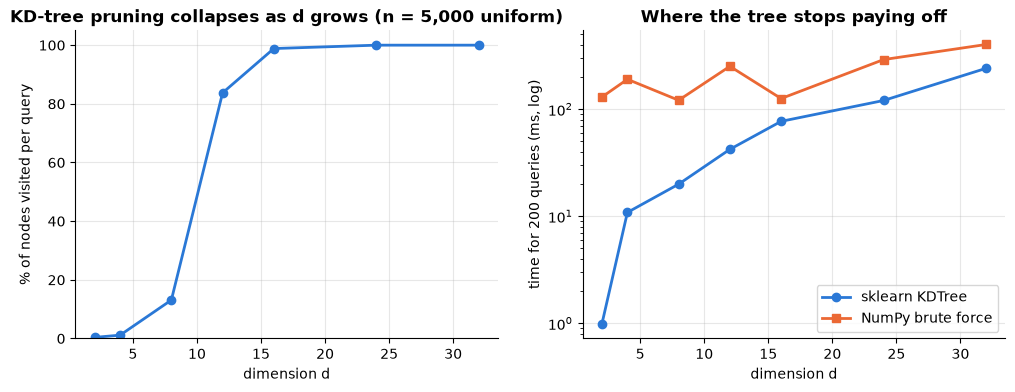

In [8]:
from sklearn.neighbors import KDTree as SkKDTree

n, n_q = 5_000, 200
rows = []
for d in [2, 4, 8, 12, 16, 24, 32]:
    X = rng.uniform(size=(n, d)); Q = rng.uniform(size=(n_q, d))
    ours = KDTree(X)
    visited = []
    for q in Q[:60]:
        ours.nearest(q); visited.append(ours.visited)
    sk = SkKDTree(X, leaf_size=30)
    t_sk = best_time(lambda: sk.query(Q, k=1), repeat=2)
    t_brute = best_time(lambda: np.argmin(((Q[:, None, :] - X[None, :, :]) ** 2).sum(-1), axis=1), repeat=2)
    _, idx = sk.query(Q, k=1)
    assert (idx[:, 0] == np.argmin(((Q[:, None, :] - X[None, :, :]) ** 2).sum(-1), axis=1)).all()
    rows.append({"dimension d": d, "our tree: % nodes visited": 100 * np.mean(visited) / n,
                 "sklearn KDTree (ms)": 1e3 * t_sk, "NumPy brute force (ms)": 1e3 * t_brute})
K = pd.DataFrame(rows)
print(K.round(2).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(K["dimension d"], K["our tree: % nodes visited"], "o-")
axes[0].set(xlabel="dimension d", ylabel="% of nodes visited per query", title="KD-tree pruning collapses as d grows (n = 5,000 uniform)", ylim=(0, 105))
axes[1].semilogy(K["dimension d"], K["sklearn KDTree (ms)"], "o-", label="sklearn KDTree")
axes[1].semilogy(K["dimension d"], K["NumPy brute force (ms)"], "s-", label="NumPy brute force")
axes[1].set(xlabel="dimension d", ylabel=f"time for {n_q} queries (ms, log)", title="Where the tree stops paying off"); axes[1].legend()
plt.show()

**What just happened?** In 2-D a query visits a tiny fraction of the 5,000 nodes. As the dimension grows the percentage climbs steeply, and by $d \approx 16$–$32$ the "tree" is visiting a large part of the data (see the table): pruning needs the distance to the splitting plane to exceed the current best distance, but in high dimensions nearest and farthest neighbours are almost the same distance away, so the far side can almost never be ruled out. That is the **curse of dimensionality**. In the right panel, scikit-learn's C-implemented KD-tree is far faster than brute force in low dimensions, and its advantage shrinks steadily as $d$ grows (exact crossover depends on the machine).

> 🎓 **Exam / interview tip:** a rule of thumb is that KD-trees are effective when $n \gg 2^d$. For 768-dimensional text embeddings, exact trees are useless; vector databases use **approximate** indexes (HNSW graphs, IVF, product quantisation) instead; see [vector databases](../../22_ML_System_Design/05_vector_databases.ipynb). Ball trees (`sklearn.neighbors.BallTree`) handle moderate dimensions and other metrics a bit better.

---
## 5. Red-black trees via 2-3-4 trees (LLRB)

> 💬 **In plain English:** a search tree that colours some links red so it can rebalance itself and never become a long chain.

**Why.** A plain BST becomes a linked list if keys arrive in sorted order (height $n$). **Balanced** BSTs guarantee height $O(\log n)$. Red-black trees are the balanced BST used in practice: Java's `TreeMap`, C++ `std::map` (in the common implementations) and the Linux kernel's scheduler and memory maps.

**Step 1: 2-3-4 trees (perfectly balanced, but awkward).** Allow nodes with 1, 2 or 3 keys (2-, 3- and 4-nodes, by number of children). Insert into a leaf; if it would overflow, **split** the 4-node and push its middle key up. All leaves stay at the same depth, so height $\le \log_2 n$.

**Step 2: red-black trees = 2-3-4 trees drawn as binary trees.** Represent a 3-node or 4-node as a small cluster of binary nodes glued by **red** links; ordinary links are **black**:

```
 2-3-4 node        red-black encoding (red link = "same 2-3-4 node")
  [ a  b ]               b                 or      a
                        /  (red)                    \  (red)
                       a                             b
 [ a b c ]               b
                       /   \   (both red)
                      a     c
```
The **red-black properties** follow directly: (1) no red link has a red child (no two reds in a row: a 2-3-4 node has at most 3 keys); (2) every path from the root to a null link has the same number of **black** links (the 2-3-4 tree is perfectly balanced). Hence height $\le 2\log_2(n+1)$.

**Step 3: left-leaning red-black trees (Sedgewick, 2008)** add one rule: a 3-node must lean left. The insertion code then needs only three local fixes, applied bottom-up after the recursive insert: rotate a right-leaning red link left; rotate two left reds in a row right; **flip colours** of a node with two red children (this is the 4-node split, passing the middle key up). Doing the colour flip on the way **down** (before recursing) gives trees that correspond to **2-3-4** trees; doing it on the way **up** gives **2-3** trees. We implement both and check all invariants on random and sorted inputs.

In [9]:
RED, BLACK = True, False


class RBNode:
    __slots__ = ("key", "val", "left", "right", "color")
    def __init__(self, key, val):
        self.key, self.val, self.left, self.right, self.color = key, val, None, None, RED   # new nodes are red


def is_red(n):
    return n is not None and n.color == RED


def rotate_left(h):
    x = h.right; h.right = x.left; x.left = h
    x.color, h.color = h.color, RED
    return x


def rotate_right(h):
    x = h.left; h.left = x.right; x.right = h
    x.color, h.color = h.color, RED
    return x


def flip_colors(h):                       # split a temporary 4-node: middle key moves up
    h.color = not h.color
    h.left.color = not h.left.color
    h.right.color = not h.right.color


class LLRB:
    def __init__(self, variant="2-3"):
        self.root, self.variant, self.n = None, variant, 0

    def put(self, key, val=None):
        self.root = self._put(self.root, key, val)
        self.root.color = BLACK

    def _put(self, h, key, val):
        if h is None:
            self.n += 1
            return RBNode(key, val)
        if self.variant == "2-3-4" and is_red(h.left) and is_red(h.right):
            flip_colors(h)                                  # split 4-nodes on the way down
        if key < h.key:   h.left = self._put(h.left, key, val)
        elif key > h.key: h.right = self._put(h.right, key, val)
        else:             h.val = val
        if is_red(h.right) and not is_red(h.left):    h = rotate_left(h)     # fix right-leaning red
        if is_red(h.left) and is_red(h.left.left):     h = rotate_right(h)    # fix two reds in a row
        if self.variant == "2-3" and is_red(h.left) and is_red(h.right):
            flip_colors(h)                                  # split 4-nodes on the way up
        return h

    def get(self, key):
        h = self.root
        while h is not None:
            if key < h.key: h = h.left
            elif key > h.key: h = h.right
            else: return h.val
        return None

    def height(self):
        def hh(n): return 0 if n is None else 1 + max(hh(n.left), hh(n.right))
        return hh(self.root)

    def check(self):
        """Verify BST order, red-black properties and left-leaning rules. Returns the black height."""
        keys = []
        def walk(n):
            if n is None:
                return 1                                    # null links count as black
            if is_red(n) and (is_red(n.left) or is_red(n.right)):
                assert not (is_red(n.left) and is_red(n.left.left)), "two reds in a row on the left"
            assert not (is_red(n) and is_red(n.right)), "red node with a red right child"
            if self.variant == "2-3":
                assert not is_red(n.right), "2-3 LLRB: no right-leaning red links"
            else:
                assert not (is_red(n.right) and not is_red(n.left)), "2-3-4 LLRB: right red only as half of a 4-node"
            lb = walk(n.left)
            keys.append(n.key)
            rb = walk(n.right)
            assert lb == rb, "black heights differ"
            return lb + (0 if is_red(n) else 1)
        assert not is_red(self.root)
        bh = walk(self.root)
        assert keys == sorted(keys) and len(keys) == self.n
        return bh


for variant in ["2-3", "2-3-4"]:
    rr = random.Random(7)
    for trial in range(60):
        t, ref = LLRB(variant), {}
        keys = [rr.randint(0, 500) for _ in range(rr.randint(0, 400))]
        if trial % 3 == 0:
            keys.sort()                                     # adversarial sorted order
        for k_ in keys:
            t.put(k_, -k_); ref[k_] = -k_
            if rr.random() < 0.05:
                t.check()                                   # check invariants in the middle too
        t.check()
        assert all(t.get(k_) == v for k_, v in ref.items()) and t.get(10_000) is None
        assert t.height() <= 2 * math.log2(t.n + 1) + 1e-9
        CHECKS[f"LLRB {variant}"] += 1
print("both LLRB variants: BST order, no double reds, equal black heights, left-leaning rule and height <= 2 log2(n+1) hold")

both LLRB variants: BST order, no double reds, equal black heights, left-leaning rule and height <= 2 log2(n+1) hold


    n insert order  plain BST height  LLRB height  2 log2(n+1)  log2(n)
  100       sorted               100            7         13.3      6.6
  100       random                14            8         13.3      6.6
 1000       sorted              1000           10         19.9     10.0
 1000       random                23           14         19.9     10.0
 5000       sorted              5000           13         24.6     12.3
 5000       random                31           18         24.6     12.3
20000       sorted             20000           15         28.6     14.3
20000       random                33           20         28.6     14.3


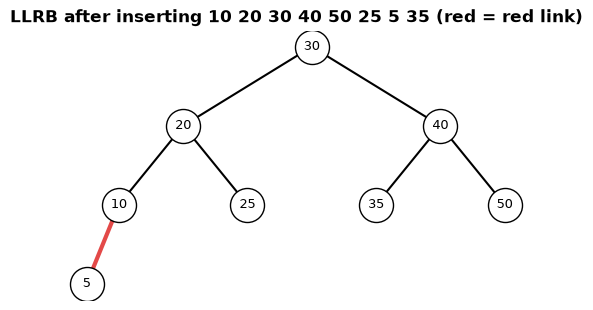

In [10]:
def plain_bst_height(keys):
    """Height of an unbalanced BST built by inserting keys in order (iterative to avoid deep recursion)."""
    left, right, depth, best = {}, {}, {}, 0
    root = None
    for k_ in keys:
        if root is None:
            root, depth[k_] = k_, 1; best = 1; continue
        cur = root
        while True:
            side = left if k_ < cur else right
            if cur in side:
                cur = side[cur]
            else:
                side[cur] = k_; depth[k_] = depth[cur] + 1; best = max(best, depth[k_]); break
    return best


rows = []
for n in [100, 1000, 5000, 20000]:
    seq = list(range(n)); rnd = random.Random(n).sample(range(n), n)
    for name, keys in [("sorted", seq), ("random", rnd)]:
        t = LLRB("2-3"); [t.put(k_) for k_ in keys]
        rows.append({"n": n, "insert order": name, "plain BST height": plain_bst_height(keys) if (name == "random" or n <= 5000) else n,
                     "LLRB height": t.height(), "2 log2(n+1)": round(2 * math.log2(n + 1), 1), "log2(n)": round(math.log2(n), 1)})
print(pd.DataFrame(rows).to_string(index=False))

t = LLRB("2-3")
for k_ in [10, 20, 30, 40, 50, 25, 5, 35]:
    t.put(k_)
G, pos = nx.DiGraph(), {}
def place(n, x, y, dx):
    if n is None: return
    pos[n.key] = (x, y)
    for child, sgn in [(n.left, -1), (n.right, 1)]:
        if child is not None:
            G.add_edge(n.key, child.key, red=child.color == RED)
            place(child, x + sgn * dx, y - 1, dx / 2)
place(t.root, 0, 0, 4)
G.add_nodes_from(pos)
fig, ax = plt.subplots(figsize=(6, 3.5))
nx.draw_networkx_nodes(G, pos, node_color="white", edgecolors="black", node_size=600, ax=ax)
nx.draw_networkx_labels(G, pos, font_size=9, ax=ax)
for u, v, dat in G.edges(data=True):
    nx.draw_networkx_edges(G, pos, edgelist=[(u, v)], edge_color=PALETTE[7] if dat["red"] else "black", width=3 if dat["red"] else 1.5, arrows=False, ax=ax)
ax.set_title("LLRB after inserting 10 20 30 40 50 25 5 35 (red = red link)"); ax.axis("off"); plt.show()

**What just happened?** Both variants kept every invariant on 120 random and sorted insertion sequences, including checks in the middle of the sequences. With **sorted** inserts a plain BST degenerates to height $n$ (5,000 for 5,000 keys; for 20,000 we did not even build it), while the LLRB height stays within $2\log_2(n+1)$ and in fact close to $\log_2 n$. The picture shows the red links: each red link glues a key to its parent into one 3-node of the corresponding 2-3 tree.

| balanced BST | height bound | rotations per insert | notes |
|---|---|---|---|
| AVL tree | $\approx 1.44\log_2 n$ | $O(1)$ (but $O(\log n)$ height updates) | stricter balance, faster lookups |
| red-black tree | $\le 2\log_2(n+1)$ | $\le 2$ | fewer rotations, standard in libraries |
| LLRB | $\le 2\log_2(n+1)$ | $O(\log n)$ | shortest code; deletion is still tricky |
| treap / skip list | $O(\log n)$ expected | $O(1)$ expected | randomised, simple ([notebook 01](01_amortized_and_randomized_algorithms.ipynb)) |
| B-tree / B+ tree | $\log_B n$ | splits | many keys per node: disks and databases |

> ⚠️ **Common mistake:** believing "red-black trees are always shorter than AVL trees". AVL trees are *more* strictly balanced (shorter); red-black trees win on cheaper updates. Also: deleting from an LLRB is noticeably harder than inserting; in exams, know the idea (push a red link down the search path) rather than memorising code.

---
## 6. Persistent data structures

> 💬 **In plain English:** keep every old version of your data by copying only the small part that changed.

**Intuition.** "Undo" in an editor, `git` history, or keeping every version of a training-data table. The naive way, copying everything at every change, costs $O(n)$ time and memory per version. A **persistent** data structure keeps **all old versions** accessible and cheap.

**Definition.** A structure is **partially persistent** if you can query any old version but update only the newest, and **fully persistent** if you can also update old versions (branching history). **Path copying** (Driscoll, Sarnak, Sleator & Tarjan, 1989, for the general theory): never modify a node; instead copy the nodes on the path from the root to the change, and let the new path point to the **unchanged** subtrees of the old version. In a balanced tree that is $O(\log n)$ new nodes per update.

```
version 0:        root0                 version 1 = set a[3] = 'X'
                 /     \                         root1
              L0        R0               (new) /     \
             /  \      /  \               L0 (shared)  R1 (new)
            a0  a1    a2  a3                          /   \
                                                    a2     X (new)
```

We implement a persistent array as a complete binary tree of tuples (immutable in Python).

In [11]:
class PersistentArray:
    """Fully persistent array by path copying. Each version is just a root; versions share subtrees."""
    def __init__(self, values):
        self.n = len(values)
        self.size = 1 << max(0, (self.n - 1).bit_length())           # pad to a power of two
        self.versions = [self._build(list(values) + [None] * (self.size - self.n), 0, self.size)]
        self.nodes_created = 0

    def _build(self, vals, lo, hi):
        if hi - lo == 1:
            return vals[lo]                                          # leaf = the value itself
        mid = (lo + hi) // 2
        return (self._build(vals, lo, mid), self._build(vals, mid, hi))

    def get(self, version, i):
        node, lo, hi = self.versions[version], 0, self.size
        while hi - lo > 1:
            mid = (lo + hi) // 2
            node, lo, hi = (node[0], lo, mid) if i < mid else (node[1], mid, hi)
        return node

    def set(self, version, i, value):
        """Create a NEW version equal to `version` except a[i] = value. Returns its number."""
        def upd(node, lo, hi):
            if hi - lo == 1:
                return value
            self.nodes_created += 1                                  # one new internal node per level
            mid = (lo + hi) // 2
            return (upd(node[0], lo, mid), node[1]) if i < mid else (node[0], upd(node[1], mid, hi))
        self.versions.append(upd(self.versions[version], 0, self.size))
        return len(self.versions) - 1

    def to_list(self, version):
        return [self.get(version, i) for i in range(self.n)]


doc = PersistentArray(list("hello world"))
v1 = doc.set(0, 0, "H")
v2 = doc.set(v1, 6, "W")
v3 = doc.set(v1, 10, "D")                         # branch from v1, not from v2
for v in range(4):
    print(f"version {v}: {''.join(doc.to_list(v))}")
print("versions 0, 1 and 2 share the untouched right half (one Python object):", doc.versions[0][1] is doc.versions[1][1] is doc.versions[2][1])

rr = random.Random(9)
for _ in range(50):                               # random branching histories vs explicit copies
    n = rr.randint(1, 60)
    base = [rr.randint(0, 9) for _ in range(n)]
    pa, copies = PersistentArray(base), [list(base)]
    for _ in range(80):
        v = rr.randrange(len(copies)); i = rr.randrange(n); x = rr.randint(0, 9)
        pa.set(v, i, x)
        c = list(copies[v]); c[i] = x; copies.append(c)
    assert all(pa.to_list(v) == copies[v] for v in range(len(copies)))
    CHECKS["persistent array"] += 1

n, n_updates = 100_000, 1_000
big = PersistentArray(list(range(n)))
for _ in range(n_updates):
    big.set(len(big.versions) - 1, rr.randrange(n), -1)
print(f"\n{n_updates} versions of a {n:,}-element array: {big.nodes_created:,} new nodes "
      f"(about {big.nodes_created // n_updates} per update = log2 of {big.size:,}) vs {n * n_updates:,} cells for full copies")

version 0: hello world
version 1: Hello world
version 2: Hello World
version 3: Hello worlD
versions 0, 1 and 2 share the untouched right half (one Python object): True



1000 versions of a 100,000-element array: 17,000 new nodes (about 17 per update = log2 of 131,072) vs 100,000,000 cells for full copies


**What just happened?** Four versions of the text coexist; version 3 branched from version 1, so this is **full** persistence. Versions 0, 1 and 2 changed only positions 0 and 6, so they physically share the untouched right half of the tree (`is` returned `True`). 50 random branching histories matched explicit copies exactly. For 1,000 versions of a 100,000-element array, path copying created 17,000 nodes (17 per update, $\log_2 131{,}072$) instead of 100 million cells.

**Trade-off:** reads become $O(\log n)$ instead of $O(1)$. That is why functional languages (Clojure, Scala, Haskell) use wide trees (32-way) to make the logarithm tiny.

**Where you meet it:** `git` stores snapshots as trees of content-addressed objects that share unchanged files and directories; copy-on-write B-trees in databases and file systems (LMDB, Btrfs, ZFS) keep old versions for consistent snapshots; React and Redux encourage immutable state updates; **JAX** treats arrays as immutable values (`x.at[i].set(v)` returns a new array).

---
## 7. An LSM tree in miniature

> 💬 **In plain English:** write new data quickly in sorted batches and merge the batches later, like a database for heavy writing.

**Problem.** A B+ tree ([DBMS 07](../../13_Databases/00_dbms_fundamentals/07_indexing_b_trees_and_hashing.ipynb)) updates pages **in place**: each random write may rewrite a whole disk page somewhere on disk. Write-heavy systems (event logs, metrics, feature logging, chat messages) want to turn random writes into **sequential** ones.

**Log-structured merge tree (O'Neil, Cheng, Gawlick & O'Neil, 1996).**
1. Writes go to an in-memory sorted buffer, the **memtable** (plus an append-only write-ahead log for crash safety, omitted here).
2. When the memtable is full it is written to disk in one sequential pass as an immutable sorted file, an **SSTable** (sorted string table).
3. Reads check the memtable, then SSTables from **newest to oldest**; the first hit wins. Deletes write a **tombstone**.
4. Each SSTable has a **Bloom filter** (see [`dsa/04`](../dsa/04_hashing.ipynb)) and min/max keys, so most files can be skipped without reading them.
5. **Compaction** merges SSTables in the background (a $k$-way merge with a heap), keeping only the newest value per key and dropping tombstones.

Used by LevelDB, RocksDB, Cassandra, HBase, ScyllaDB, and the storage engines of many time-series and vector databases.

In [12]:
class Bloom:
    def __init__(self, n_items, bits_per_item=10, k=7):
        self.m = max(8, n_items * bits_per_item); self.k = k
        self.bits = bytearray((self.m + 7) // 8)

    def _positions(self, key):
        h = hashlib.blake2b(str(key).encode(), digest_size=16).digest()
        a, b = int.from_bytes(h[:8], "little"), int.from_bytes(h[8:], "little")
        return [(a + i * b) % self.m for i in range(self.k)]     # double hashing

    def add(self, key):
        for p in self._positions(key):
            self.bits[p // 8] |= 1 << (p % 8)

    def might_contain(self, key):
        return all(self.bits[p // 8] >> (p % 8) & 1 for p in self._positions(key))


TOMBSTONE = "__deleted__"


class MiniLSM:
    def __init__(self, directory, memtable_limit=500, compact_at=4, use_bloom=True):
        self.dir, self.limit, self.compact_at, self.use_bloom = directory, memtable_limit, compact_at, use_bloom
        self.memtable = {}
        self.tables = []                           # newest last: dicts with path, min, max, bloom
        self.file_counter = 0
        self.stats = Counter()

    def put(self, key, value):
        self.memtable[key] = value
        self.stats["user bytes"] += len(json.dumps([key, value]))
        if len(self.memtable) >= self.limit:
            self._flush()

    def delete(self, key):
        self.put(key, TOMBSTONE)

    def _write_table(self, items):
        path = os.path.join(self.dir, f"sst_{self.file_counter:05d}.json"); self.file_counter += 1
        bloom = Bloom(len(items))
        data = json.dumps(items)                   # one sequential write of the sorted (key, value) list
        with open(path, "w") as f:
            f.write(data)
        self.stats["disk bytes written"] += len(data)
        for k_, _ in items:
            bloom.add(k_)
        return {"path": path, "min": items[0][0], "max": items[-1][0], "bloom": bloom, "n": len(items)}

    def _flush(self):
        items = sorted(self.memtable.items())
        self.tables.append(self._write_table(items))
        self.memtable = {}
        self.stats["flushes"] += 1
        if len(self.tables) >= self.compact_at:
            self._compact()

    def _read_table(self, t):
        self.stats["disk reads"] += 1
        with open(t["path"]) as f:
            return [tuple(kv) for kv in json.load(f)]

    def _compact(self):
        """Size-tiered compaction: merge all tables, newest value wins, drop tombstones."""
        runs = []
        for age, t in enumerate(self.tables):      # older tables have smaller age
            runs.append([(k_, -age, v) for k_, v in self._read_table(t)])
        merged, last = [], object()
        for k_, neg_age, v in heapq.merge(*runs):  # sorted by key, then newest first
            if k_ != last:
                last = k_
                if v != TOMBSTONE:
                    merged.append((k_, v))
        for t in self.tables:
            os.remove(t["path"])
        self.tables = [self._write_table(merged)] if merged else []
        self.stats["compactions"] += 1

    def get(self, key):
        if key in self.memtable:
            v = self.memtable[key]
            return None if v == TOMBSTONE else v
        for t in reversed(self.tables):            # newest to oldest
            if not (t["min"] <= key <= t["max"]):
                continue                           # fence pointers: key outside this file's range
            if self.use_bloom and not t["bloom"].might_contain(key):
                self.stats["bloom skips"] += 1
                continue                           # definitely not in this file: no disk read
            items = self._read_table(t)
            i = bisect.bisect_left(items, (key,))
            if i < len(items) and items[i][0] == key:
                v = items[i][1]
                return None if v == TOMBSTONE else v
        return None


workdir = tempfile.mkdtemp(prefix="mini_lsm_")
try:
    results = {}
    for use_bloom in [True, False]:
        rr = random.Random(10)
        db, ref = MiniLSM(os.path.join(workdir, f"bloom_{use_bloom}"), compact_at=10, use_bloom=use_bloom), {}
        os.makedirs(db.dir)
        for step in range(8_000):                  # random workload, checked against a dict
            k_ = 2 * rr.randrange(5_000)           # only EVEN keys are ever written
            u = rr.random()
            if u < 0.8:
                db.put(k_, step); ref[k_] = step
            elif u < 0.9:
                db.delete(k_); ref.pop(k_, None)
            else:
                assert db.get(k_) == ref.get(k_)
                CHECKS["mini LSM get"] += 1
        reads_before = db.stats["disk reads"]
        skips_before = db.stats["bloom skips"]
        for k_ in range(1, 601, 2):                # 300 lookups of ODD keys: inside every file's key range, but absent
            assert db.get(k_) is None
        results[use_bloom] = {"SSTables now": len(db.tables), "flushes": db.stats["flushes"], "compactions": db.stats["compactions"],
                              "write amplification": round(db.stats["disk bytes written"] / db.stats["user bytes"], 2),
                              "disk reads for 300 missing keys": db.stats["disk reads"] - reads_before,
                              "Bloom skips during those lookups": db.stats["bloom skips"] - skips_before}
    print(pd.DataFrame(results).rename(columns={True: "with Bloom filters", False: "without"}).to_string())
    print("\nfiles on disk:", sorted(os.listdir(os.path.join(workdir, "bloom_True"))))
finally:
    shutil.rmtree(workdir)                         # always clean up the temporary directory
print("temporary directory removed:", not os.path.exists(workdir))

                                  with Bloom filters  without
SSTables now                                    4.00     4.00
flushes                                        13.00    13.00
compactions                                     1.00     1.00
write amplification                             1.47     1.47
disk reads for 300 missing keys                11.00  1105.00
Bloom skips during those lookups             1094.00     0.00

files on disk: ['sst_00010.json', 'sst_00011.json', 'sst_00012.json', 'sst_00013.json']
temporary directory removed: True


**What just happened?** The mini LSM tree answered every `get` in an 8,000-operation random workload (puts, deletes, gets) exactly like a Python dict, while flushing memtables to sorted files and compacting them. Two numbers explain the design:
- **Write amplification** (bytes written to disk ÷ bytes written by the user) is above 1, because compaction rewrites data. That is the price LSM trees pay for sequential writes; levelled compaction (RocksDB's default) trades more write amplification for fewer files to read.
- **Bloom filters** made lookups of missing keys almost free. The absent odd keys lie inside every SSTable's key range, so without filters 300 lookups cost 1,105 file reads (almost every SSTable, every time); with 10 bits per key and 7 hash functions the false-positive rate is about 1%, and only 11 reads remain (1,094 skipped).

| | B+ tree ([DBMS 07](../../13_Databases/00_dbms_fundamentals/07_indexing_b_trees_and_hashing.ipynb)) | LSM tree |
|---|---|---|
| write path | in-place page updates (random I/O) | append to memtable, sequential flushes |
| read path | one root-to-leaf path, $O(\log_B n)$ pages | memtable + several SSTables (Bloom filters help) |
| write amplification | moderate | higher (compaction rewrites) |
| read amplification | low | higher, especially for range scans |
| space amplification | page fill factor | obsolete versions until compaction |
| typical users | PostgreSQL, MySQL InnoDB, SQLite | RocksDB, Cassandra, LevelDB, HBase |

---
## 8. Gap buffers and ropes

> 💬 **In plain English:** two tricks text editors use so typing in the middle of a long document stays fast.

**Problem.** A text editor holds a document of $n$ characters and the user types at the cursor. With a plain Python string or array, inserting in the middle shifts everything after it: $O(n)$ per keystroke.

**Gap buffer** (Emacs): keep an array with an empty **gap** at the cursor. Typing fills the gap ($O(1)$); moving the cursor by $d$ positions moves $d$ characters across the gap ($O(d)$); when the gap is full, grow it (amortised $O(1)$ like a dynamic array). Great for editing that happens near one place.

**Rope** (Boehm, Atkinson & Plass, 1995): a binary tree whose leaves hold short strings and whose internal nodes store the **weight** (length of the left subtree). Concatenation is $O(1)$ (a new root), indexing and split are $O(\text{depth})$. Good for very large texts and many edits in different places. VS Code uses a related **piece table / piece tree**. LLM serving systems stream tokens into growing text buffers with the same concerns.

In [13]:
class GapBuffer:
    def __init__(self, text="", gap=16):
        self.buf = list(text) + [None] * gap
        self.gap_start, self.gap_end = len(text), len(text) + gap     # gap = buf[gap_start:gap_end]
        self.moves = 0

    def move_to(self, pos):
        while self.gap_start > pos:                                   # move gap left: shift one char right
            self.gap_start -= 1; self.gap_end -= 1
            self.buf[self.gap_end] = self.buf[self.gap_start]; self.moves += 1
        while self.gap_start < pos:                                   # move gap right
            self.buf[self.gap_start] = self.buf[self.gap_end]
            self.gap_start += 1; self.gap_end += 1; self.moves += 1

    def insert(self, ch):
        if self.gap_start == self.gap_end:                            # gap full: double the buffer
            extra = max(16, len(self.buf))
            self.buf[self.gap_end:self.gap_end] = [None] * extra
            self.gap_end += extra
        self.buf[self.gap_start] = ch
        self.gap_start += 1

    def delete_before(self):
        if self.gap_start > 0:
            self.gap_start -= 1                                       # just widen the gap

    def text(self):
        return "".join(self.buf[:self.gap_start] + self.buf[self.gap_end:])


class Rope:
    LEAF = 8
    def __init__(self, s="", left=None, right=None):
        if left is None and len(s) > Rope.LEAF:                       # split long strings into a balanced tree
            mid = len(s) // 2
            left, right, s = Rope(s[:mid]), Rope(s[mid:]), ""
        self.left, self.right, self.s = left, right, s
        self.weight = len(left) if left is not None else len(s)

    def __len__(self):
        return self.weight + (len(self.right) if self.right is not None else 0) if self.left is not None else len(self.s)

    def __add__(self, other):
        return Rope(left=self, right=other)                           # O(1) concatenation

    def index(self, i):
        node = self
        while node.left is not None:                                  # walk down using weights
            if i < node.weight:
                node = node.left
            else:
                i -= node.weight; node = node.right
        return node.s[i]

    def __str__(self):
        return self.s if self.left is None else str(self.left) + str(self.right)


rr = random.Random(11)
for _ in range(200):                                                  # gap buffer vs a Python list
    gb, ref, cur = GapBuffer("abc"), list("abc"), 3
    for _ in range(100):
        op = rr.random()
        if op < 0.3:
            cur = rr.randint(0, len(ref)); gb.move_to(cur)
        elif op < 0.85:
            ch = rr.choice("xyz"); gb.insert(ch); ref.insert(cur, ch); cur += 1
        elif cur > 0:
            gb.delete_before(); ref.pop(cur - 1); cur -= 1
    assert gb.text() == "".join(ref)
    CHECKS["gap buffer"] += 1
    a = "".join(rr.choice("abcdef") for _ in range(rr.randint(1, 50))); b = "".join(rr.choice("uvw") for _ in range(rr.randint(1, 50)))
    r = Rope(a) + Rope(b)
    assert str(r) == a + b and len(r) == len(a + b) and all(r.index(i) == (a + b)[i] for i in range(len(a + b)))
    CHECKS["rope"] += 1

gb = GapBuffer("The quick fox")
gb.move_to(10)
for ch in "brown ":
    gb.insert(ch)
print(repr(gb.text()), f"| characters moved: {gb.moves}")
r = Rope("Large language models ") + Rope("generate text one token at a time.")
print(str(r), "| r.index(6) =", repr(r.index(6)), "| length", len(r))

'The quick brown fox' | characters moved: 3
Large language models generate text one token at a time. | r.index(6) = 'l' | length 56


**What just happened?** Typing "brown " in the middle of "The quick fox" moved only the 3 characters between the end of the text and the cursor ("fox") across the gap; then each keystroke was $O(1)$. The rope concatenated two texts without copying them and indexed into the result by walking down the weights. Both matched plain Python lists/strings on 200 random edit sequences.

---
## 9. Comparison table

> 💬 **In plain English:** all the structures side by side, and where AI systems use them.

| structure | main operations | time | space | use it when |
|---|---|---|---|---|
| sparse table | range min/max/gcd | $O(1)$ query, $O(n\log n)$ build | $O(n \log n)$ | static data, many queries |
| sqrt decomposition | range query + point update | $O(\sqrt n)$ / $O(1)$ | $O(n)$ | quick to code, flexible operations |
| segment tree ([`dsa/11`](../dsa/11_advanced_tries_strings_and_range_queries.ipynb)) | range query + update | $O(\log n)$ | $O(n)$ | dynamic ranges, lazy range updates |
| suffix array + LCP | substring search, repeats, distinct substrings | $O(n\log^2 n)$ build here; $O(m \log n)$ search | $O(n)$ | full-text indexes, dedup, bioinformatics |
| interval tree | all intervals overlapping a query | $O(\log n + k)$-ish | $O(n)$ | calendars, genomic regions, time ranges |
| KD-tree | nearest neighbour, range search | $O(\log n)$ typical in low $d$; degrades to $O(n)$ | $O(n)$ | $d \lesssim 10$–$20$; use ANN indexes above |
| red-black / LLRB tree | ordered map: insert, search, min, successor | $O(\log n)$ worst case | $O(n)$ | sorted keys with updates (`TreeMap`, `std::map`) |
| persistent array (path copying) | update creates a version; read any version | $O(\log n)$ | $O(\log n)$ per update | undo, snapshots, branching histories |
| LSM tree | put / get / delete, range scans | writes sequential; reads check several files | $O(n)$ + obsolete data | write-heavy stores (RocksDB, Cassandra) |
| gap buffer / rope | edit text at a cursor / anywhere | $O(1)$ near cursor / $O(\log n)$ | $O(n)$ | text editors, streaming text |

In [14]:
summary = pd.DataFrame(sorted(CHECKS.items()), columns=["structure", "random checks passed"])
print(summary.to_string(index=False))
print("\nevery assert passed")

                structure  random checks passed
KD-tree nearest neighbour                  1000
                 LLRB 2-3                    60
               LLRB 2-3-4                    60
               gap buffer                   200
            interval tree                  3000
             mini LSM get                  1520
         persistent array                    50
            range queries                  9000
                     rope                   200
       suffix array + LCP                   500
suffix-array applications                   300

every assert passed


## 🔗 How this connects to modern AI

- **Suffix arrays at LLM scale.** Lee et al. (2021) removed exact repeated substrings (50+ tokens) from training corpora using a suffix array over the whole dataset; together with MinHash near-dedup ([notebook 06](06_streaming_and_sketching_algorithms.ipynb)) this reduced memorisation. **Infini-gram** (Liu et al., 2024) builds suffix arrays over trillions of tokens to answer $n$-gram counts for arbitrarily long $n$ in milliseconds, and to check whether a model's output appears verbatim in its training data.
- **Nearest-neighbour search.** KD-trees and ball trees power exact kNN in scikit-learn ([KNN](../../03_Machine_Learning/01_supervised/07_knn.ipynb)) for low-dimensional features; for embeddings, the curse of dimensionality you measured is why RAG systems use approximate indexes ([vector databases](../../22_ML_System_Design/05_vector_databases.ipynb), [vector DB hands-on](../../13_Databases/03_vector_db/01_vector_databases.ipynb), [RAG](../../08_LLM/02_rag/01_rag_fundamentals.ipynb)).
- **LSM trees under feature stores and logs.** Online feature stores, event logs and many vector databases sit on LSM engines (RocksDB, Cassandra) because ML systems write far more than they read ([feature stores](../../15_MLOps/12_feature_stores.ipynb), [NoSQL data stores](../../22_ML_System_Design/04_nosql_and_data_stores.ipynb)).
- **Interval trees** for time-range joins (which model version served which request?), genomics pipelines, and scheduling GPU reservations.
- **Persistence / immutability** in JAX (functional array updates), data versioning ([DVC](../../15_MLOps/02_data_versioning/01_dvc.ipynb)) and experiment snapshots.
- **Balanced trees** inside schedulers and ordered indexes (e.g. sorted sets in Redis use skip lists, the Linux CFS scheduler used a red-black tree).
- **Ropes / piece tables** in code editors with AI completion, and token buffers in LLM streaming servers.

## Recap
- **Sparse table**: $O(1)$ idempotent range queries on static data; **sqrt decomposition**: $O(\sqrt n)$ queries with $O(1)$ updates.
- **Suffix array** = sorted suffixes; **LCP** = neighbour overlaps (Kasai, $O(n)$); together they answer substring, repeat and distinct-substring questions.
- **Interval tree** = BST by start + `max_end` augmentation; prune subtrees that end too early.
- **KD-tree**: median splits by alternating axes; prune the far side when the split plane is farther than the best distance; useless in high dimensions.
- **Red-black trees** are 2-3-4 trees in disguise; **LLRB** insert = rotate left, rotate right, flip colours; height $\le 2\log_2(n+1)$.
- **Persistence by path copying**: $O(\log n)$ new nodes per version; old versions share everything else.
- **LSM tree**: memtable → sorted immutable SSTables → compaction; Bloom filters make negative lookups cheap; trades write amplification for sequential writes.
- **Gap buffer** for local edits, **rope** for large texts and frequent concatenation.

## Practice problems

Solutions are hidden; try first. Every code solution was run and tested when this notebook was built.

**1. (Easy, conceptual)** Why can a sparse table answer range-**minimum** queries in $O(1)$ but not range-**sum** queries? Which other operations work?

<details><summary>Show solution</summary>

The $O(1)$ query covers $[l, r]$ with two power-of-two blocks that may **overlap**. For min, counting an element twice changes nothing ($\min(x, x) = x$, the operation is **idempotent**). For sums the overlap would be double-counted. Any associative and idempotent operation works: max, gcd, bitwise AND/OR. (Sums can use a sparse table in $O(\log n)$ with disjoint blocks, but prefix sums are simpler.)

</details>

**2. (Easy, conceptual)** Build the suffix array and LCP array of `abab` by hand. How many distinct substrings does it have?

<details><summary>Show solution</summary>

Suffixes: 0 `abab`, 1 `bab`, 2 `ab`, 3 `b`. Sorted: `ab` (2), `abab` (0), `b` (3), `bab` (1). SA = [2, 0, 3, 1], LCP = [0, 2, 0, 1]. Distinct substrings $= \frac{4 \cdot 5}{2} - (2 + 0 + 1) = 10 - 3 = 7$: a, b, ab, ba, aba, bab, abab.

</details>

**3. (Medium, coding)** Find the **longest common substring** of two strings using one suffix array over `a + separator + b`.

<details><summary>Show solution</summary>

```python
def longest_common_substring(a, b):
    """Longest common substring of a and b via the suffix array of a + sep + b."""
    s = a + "\x00" + b                              # separator smaller than any letter, not in a or b
    sa = suffix_array_doubling(s)
    lcp = lcp_kasai(s, sa)
    best, pos = 0, 0
    for i in range(1, len(s)):
        x, y = sa[i - 1], sa[i]
        if (x < len(a)) != (y < len(a)):            # neighbours come from different strings
            if lcp[i] > best:
                best, pos = lcp[i], sa[i]
    return s[pos:pos + best]
```
The longest common substring is a common prefix of a suffix of `a` and a suffix of `b`; the best such pair is adjacent in the sorted order of all suffixes of the combined string (the separator stops matches from running across the boundary). Tested against brute force on 300 random pairs.

</details>

**4. (Medium, coding)** Extend the KD-tree search to return the **$k$ nearest** neighbours.

<details><summary>Show solution</summary>

```python
def k_nearest(tree, q, k):
    """k nearest neighbours with a KD-tree: keep a max-heap (negated distances) of the best k."""
    import heapq, math
    import numpy as np
    q = np.asarray(q, dtype=float)
    heap = []                                       # (-distance, index)
    def search(node):
        if node is None:
            return
        p = tree.P[node.idx]
        d = math.dist(p, q)
        if len(heap) < k:
            heapq.heappush(heap, (-d, node.idx))
        elif d < -heap[0][0]:
            heapq.heapreplace(heap, (-d, node.idx))
        diff = q[node.axis] - p[node.axis]
        near, far = (node.left, node.right) if diff < 0 else (node.right, node.left)
        search(near)
        if len(heap) < k or abs(diff) < -heap[0][0]:   # prune with the k-th best distance
            search(far)
    search(tree.root)
    return sorted((-nd, i) for nd, i in heap)
```
Keep the $k$ best in a max-heap; prune the far side only when the plane is farther than the current $k$-th best distance (and only once you have $k$ candidates). Tested against sorted brute-force distances.

</details>

**5. (Easy, coding, interview classic)** Given meetings as $[start, end)$ pairs, can one person attend all of them?

<details><summary>Show solution</summary>

```python
def can_attend_all(meetings):
    """True if no two meetings overlap ([start, end) intervals). Sort by start, compare neighbours."""
    meetings = sorted(meetings)
    return all(meetings[i][1] <= meetings[i + 1][0] for i in range(len(meetings) - 1))
```
$O(n \log n)$: after sorting by start, any overlap must occur between neighbours. Use the interval tree (Section 3) when meetings arrive one at a time and each must be checked on arrival.

</details>

**6. (Medium, conceptual)** Insert the keys 1, 2, 3, 4, 5, 6, 7 in this order into a 2-3 LLRB. What is the final height? Into a plain BST?

<details><summary>Show solution</summary>

Plain BST: a right-leaning chain of height 7. LLRB: after the rotations and colour flips, inserting 1..7 produces a perfectly balanced tree with root 4, children 2 and 6, and leaves 1, 3, 5, 7, all black: height 3 ($= \log_2 8$). (You can verify with the `LLRB` class: `t = LLRB(); [t.put(k) for k in range(1, 8)]; t.height()`.)

</details>

**7. (Hard, conceptual)** An LSM tree has 10 SSTables, each with a Bloom filter at 10 bits per key and 7 hash functions (false-positive rate about 0.8%). Roughly how many disk reads does a lookup of a **missing** key cost on average, with and without the filters? Why do range scans not benefit?

<details><summary>Show solution</summary>

Without filters every SSTable whose key range covers the key must be read: up to **10** reads. With filters each file is read only on a false positive: expected $10 \times 0.008 \approx$ **0.08** reads. A range scan asks "all keys between $x$ and $y$", which a Bloom filter (a membership test for single keys) cannot answer, so every overlapping SSTable must be read and merged. (RocksDB adds **prefix Bloom filters** for scans with a common prefix.)

</details>

**8. (Hard, conceptual)** Why does path copying give $O(\log n)$ space per update for a balanced tree but $O(n)$ for a singly linked list updated at its **end**?

<details><summary>Show solution</summary>

Path copying copies every node from the root to the changed node, because each of them points (directly or indirectly) to the changed one. In a balanced tree that path has $O(\log n)$ nodes. In a singly linked list the "root" is the head and the path to the last element is the whole list, so all $n$ nodes are copied. Updates at the **head** of a list are $O(1)$ (the classic persistent stack), which is why functional languages favour prepending.

</details>

## Further reading (additional learning resources)
- Cormen, Leiserson, Rivest, Stein, *Introduction to Algorithms* (CLRS, 4th ed., 2022): ch. 13 (red-black trees), ch. 17 (augmenting data structures, §17.3 interval trees), ch. 18 (B-trees).
- Sedgewick & Wayne, *Algorithms* (4th ed.), §3.3 balanced search trees; R. Sedgewick, "Left-leaning Red-Black Trees" (2008).
- Manber & Myers, "Suffix arrays: a new method for on-line string searches", 1990; Kasai et al., "Linear-time longest-common-prefix computation", CPM 2001; Gusfield, *Algorithms on Strings, Trees and Sequences* (1997).
- Bentley, "Multidimensional binary search trees used for associative searching", *CACM* 1975.
- Driscoll, Sarnak, Sleator & Tarjan, "Making data structures persistent", *JCSS* 1989; Okasaki, *Purely Functional Data Structures* (1998).
- O'Neil, Cheng, Gawlick & O'Neil, "The log-structured merge-tree (LSM-tree)", *Acta Informatica* 1996; the RocksDB wiki on compaction.
- Lee et al., "Deduplicating Training Data Makes Language Models Better" (2021); Liu et al., "Infini-gram" (2024).
- cp-algorithms (free): [suffix array](https://cp-algorithms.com/string/suffix-array.html), [sqrt decomposition](https://cp-algorithms.com/data_structures/sqrt_decomposition.html). GeeksforGeeks: [Interval Tree](https://www.geeksforgeeks.org/interval-tree/), [K-D Tree](https://www.geeksforgeeks.org/search-and-insertion-in-k-dimensional-tree/), [Red-Black Tree](https://www.geeksforgeeks.org/introduction-to-red-black-tree/).

## Next notebook
➡️ [09 · Coding interview workbook](09_coding_interview_workbook.ipynb): about 40 tested problems grouped by pattern, to practise everything in this series. If you skipped the first half of the series, start at [01 · Amortized and randomized algorithms](01_amortized_and_randomized_algorithms.ipynb).